In [20]:
import pandas as pd
import numpy as np

In [196]:
CSV_PATHS = [
    "results_t2_gpt-4o_20260625_1054.csv",
    "results_t2_gpt-4o-mini_20260625_1108.csv",
    "results_t2_Qwen_Qwen2.5-7B-Instruct_20260625_1221.csv",
    "results_t2_Qwen_Qwen3-14B_20260625_1135.csv",
    "results_t2_meta-llama_Meta-Llama-3.1-8B-Instruct_20260625_1747.csv"
    
]

In [197]:
dfs = []

for path in CSV_PATHS:

    df_model = pd.read_csv(path)

    # opcional: guardar origem do arquivo
    df_model["source_file"] = path

    dfs.append(df_model)

# concatena tudo
df = pd.concat(dfs, ignore_index=True)

# garante tipos corretos
df["deepeval_score"] = pd.to_numeric(
    df["deepeval_score"],
    errors="coerce"
)

print(df.shape)
print(df.columns.tolist())

print("\n=== MODELS ===")
print(df["model"].value_counts())

(500, 21)
['provider', 'model', 'temperature', 'n_runs', 'case_id', 'input_type', 'query', 'expected_tool', 'case_success_rate', 'run', 'tool_called', 'first_tool', 'correct', 'failure_type', 'tool_calls_info', 'final_content', 'deepeval_score', 'deepeval_reason', 'deepeval_error', 'error', 'source_file']

=== MODELS ===
model
gpt-4o                                   100
gpt-4o-mini                              100
Qwen/Qwen2.5-7B-Instruct                 100
Qwen/Qwen3-14B                           100
meta-llama/Meta-Llama-3.1-8B-Instruct    100
Name: count, dtype: int64


In [198]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

df.head()

,provider,model,temperature,n_runs,case_id,input_type,query,expected_tool,case_success_rate,run,tool_called,first_tool,correct,failure_type,tool_calls_info,final_content,deepeval_score,deepeval_reason,deepeval_error,error,source_file
0,openai,gpt-4o,0.7,10,ex_1,cancel_explicit,Cancel order ORD-2020 for customer Laura Mendes due to change of mind.,['cancel_order'],20.0,0,False,NaN,False,omission,[],"I need to check the status of order ORD-2020 first to determine the appropriate action. Please provide the current status of the order (e.g., PENDING, SHIPPED, DELIVERED) if you have it, or let me know if you need me to look it up.",0.4,"The system initiated the process by requesting the order status, which is a preliminary step towards cancellation. However, it did not complete the task of canceling the order as requested.",NaN,NaN,results_t2_gpt-4o_20260625_1054.csv
1,openai,gpt-4o,0.7,10,ex_1,cancel_explicit,Cancel order ORD-2020 for customer Laura Mendes due to change of mind.,['cancel_order'],20.0,1,True,search_client,False,wrong_tool,"[{""name"": ""search_client"", ""args"": {""query"": ""Laura Mendes""}}]",I found the customer profile for Laura Mendes. Could you please provide the current status of order ORD-2020 so I can determine the appropriate action?,0.5,"The system successfully identified the customer profile for Laura Mendes, which is a crucial step in the cancellation process. However, it did not complete the task of canceling the order ORD-2020, as it required additional information to proceed. This partial completion results in a verdict of 0.5.",NaN,NaN,results_t2_gpt-4o_20260625_1054.csv
2,openai,gpt-4o,0.7,10,ex_1,cancel_explicit,Cancel order ORD-2020 for customer Laura Mendes due to change of mind.,['cancel_order'],20.0,2,False,NaN,False,omission,[],Could you please provide the current status of order ORD-2020? This will help me determine the appropriate action to take.,0.4,"The system initiated the process by requesting the order status, which is a preliminary step towards cancellation. However, it did not complete the task of canceling the order as requested.",NaN,NaN,results_t2_gpt-4o_20260625_1054.csv
3,openai,gpt-4o,0.7,10,ex_1,cancel_explicit,Cancel order ORD-2020 for customer Laura Mendes due to change of mind.,['cancel_order'],20.0,3,False,NaN,False,omission,[],Could you please provide the status of the order ORD-2020? This will help me determine the appropriate action to take based on the order status.,0.4,"The system initiated the process by checking the order status, which is a necessary step for cancellation. However, it did not complete the task of actually canceling the order for Laura Mendes.",NaN,NaN,results_t2_gpt-4o_20260625_1054.csv
4,openai,gpt-4o,0.7,10,ex_1,cancel_explicit,Cancel order ORD-2020 for customer Laura Mendes due to change of mind.,['cancel_order'],20.0,4,False,NaN,False,omission,[],Can you please provide me with the status of order ORD-2020? It is necessary to determine whether we can cancel or refund the order based on its current status.,0.4,"The system initiated the process by checking the order status, which is a necessary step towards cancellation. However, it did not complete the task of canceling the order or confirming the cancellation for the customer.",NaN,NaN,results_t2_gpt-4o_20260625_1054.csv


In [199]:
df_li = df[df["case_id"].str.startswith("am_")].copy()
df_ex = df[df["case_id"].str.startswith("ex_")].copy()
df_eq = df[df["case_id"].str.startswith("eq_")].copy()

In [ ]:
# analise do df eq

In [208]:
print(df_eq["first_tool"].value_counts(dropna=False))

first_tool
get_client       80
NaN              14
search_client     6
Name: count, dtype: int64


In [209]:
print(
    pd.crosstab(
        df_eq["model"],
        df_eq["first_tool"].fillna("No Tool")
    )
)

first_tool                             No Tool  get_client  search_client
model                                                                    
Qwen/Qwen2.5-7B-Instruct                     0          20              0
Qwen/Qwen3-14B                               0          20              0
gpt-4o                                       0          20              0
gpt-4o-mini                                  0          20              0
meta-llama/Meta-Llama-3.1-8B-Instruct       14           0              6


In [215]:
import json
import pandas as pd

df_eq = df[df["case_id"].str.startswith("eq_")].copy()

def classify_calls(tool_calls):
    if pd.isna(tool_calls):
        return "No Tool"

    calls = json.loads(tool_calls)
    names = [c["name"] for c in calls]

    if len(names) == 0:
        return "No Tool"

    repeated = len(names) != len(set(zip(names, [str(c.get("args")) for c in calls])))
    multiple_tools = len(set(names)) > 1

    if multiple_tools and repeated:
        return "Multiple + Repeated"
    elif multiple_tools:
        return "Multiple Tools"
    elif repeated:
        return "Repeated Calls"
    else:
        return "Single Tool"

df_eq["behavior"] = df_eq["tool_calls_info"].apply(classify_calls)

# Contagem por modelo
counts = pd.crosstab(df_eq["model"], df_eq["behavior"])

# Porcentagem por modelo
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

print("Counts")
counts

Counts


behavior,Multiple + Repeated,Multiple Tools,No Tool,Single Tool
model,,,,
Qwen/Qwen2.5-7B-Instruct,0,10,0,10
Qwen/Qwen3-14B,0,10,0,10
gpt-4o,0,10,0,10
gpt-4o-mini,0,10,0,10
meta-llama/Meta-Llama-3.1-8B-Instruct,4,0,14,2


In [200]:
import ast
import json

# ==========================================
# RECALCULATE "correct"
# ==========================================

def safe_parse(value):
    """
    Safely parse strings that may contain:
    - Python lists/dicts
    - JSON
    - already parsed objects
    """
    if isinstance(value, (list, dict)):
        return value

    if pd.isna(value):
        return []

    try:
        return ast.literal_eval(value)
    except Exception:
        try:
            return json.loads(value)
        except Exception:
            return []


def extract_tool_names(tool_calls_info):
    """
    Extract tool names from tool_calls_info.
    Adjust this if your structure differs.
    """
    parsed = safe_parse(tool_calls_info)

    tool_names = []

    for item in parsed:
        if isinstance(item, dict):
            # common patterns
            if "tool_name" in item:
                tool_names.append(item["tool_name"])

            elif "name" in item:
                tool_names.append(item["name"])

            elif "tool" in item:
                tool_names.append(item["tool"])

    return tool_names


def compute_correct(row):
    expected_tools = safe_parse(row["expected_tool"])

    if isinstance(expected_tools, str):
        expected_tools = [expected_tools]

    called_tools = extract_tool_names(row["tool_calls_info"])

    # TRUE if ANY called tool is in expected_tool
    return any(
        tool in expected_tools
        for tool in called_tools
    )


# recompute correct column
df_li["correct"] = df_li.apply(compute_correct, axis=1)
df_ex["correct"] = df_ex.apply(compute_correct, axis=1)
df_eq["correct"] = df_eq.apply(compute_correct, axis=1)

# ==========================================
# PREP
# ==========================================

df_li["deepeval_score"] = pd.to_numeric(
    df_li["deepeval_score"],
    errors="coerce"
)
df_ex["deepeval_score"] = pd.to_numeric(
    df_ex["deepeval_score"],
    errors="coerce"
)

df_eq["deepeval_score"] = pd.to_numeric(
    df_eq["deepeval_score"],
    errors="coerce"
)



THRESHOLD = 0.7

df_li["judge_approved"] = df_li["deepeval_score"] >= THRESHOLD
df_ex["judge_approved"] = df_ex["deepeval_score"] >= THRESHOLD
df_eq["judge_approved"] = df_eq["deepeval_score"] >= THRESHOLD


# false positives:
# judge approved + deterministic failure
fp_df = df_li[
    (df_li["judge_approved"] == True) &
    (df_li["correct"] == False)
].copy()

# deterministic failures
failures_df = df_li[
    df_li["correct"] == False
].copy()

# ==========================================
# SAVE
# ==========================================

fp_df.to_csv("false_positives.csv", index=False)
failures_df.to_csv("deterministic_failures.csv", index=False)

print(f"False positives em df_li: {len(fp_df)}")
print(f"Deterministic failures: {len(failures_df)}")

False positives em df_li: 14
Deterministic failures: 51


In [201]:
# salvando fp e fn

THRESHOLD = 0.7

df_li["judge_approved"] = df_li["deepeval_score"] >= THRESHOLD
df_ex["judge_approved"] = df_ex["deepeval_score"] >= THRESHOLD

# ==========================================
# FALSE POSITIVES
# ==========================================

fp_df = df_li[
    (df_li["judge_approved"]) &
    (~df_li["correct"])
].copy()

# ==========================================
# FALSE NEGATIVES
# ==========================================

fn_df = df_li[
    (~df_li["judge_approved"]) &
    (df_li["correct"])
].copy()

# ==========================================
# ALL MISCLASSIFICATIONS
# ==========================================

misclassification_df = df_li[
    df_li["judge_approved"] != df_li["correct"]
].copy()

# ==========================================
# DETERMINISTIC FAILURES (opcional)
# ==========================================

failures_df = df_li[
    ~df_li["correct"]
].copy()

# ==========================================
# SAVE
# ==========================================

fp_df.to_csv("false_positives.csv", index=False)
fn_df.to_csv("false_negatives.csv", index=False)
misclassification_df.to_csv("misclassifications.csv", index=False)
failures_df.to_csv("deterministic_failures.csv", index=False)

print(f"False Positives : {len(fp_df)}")
print(f"False Negatives : {len(fn_df)}")
print(f"Misclassifications: {len(misclassification_df)}")
print(f"Deterministic failures: {len(failures_df)}")

False Positives : 14
False Negatives : 16
Misclassifications: 30
Deterministic failures: 51


In [205]:
# =============================
# OVERALL AGREEMENT
# =============================

agreement = (
    df_li["judge_approved"] == df_li["correct"]
).mean()

print("\n=== OVERALL AGREEMENT ambigous ===")
print(round(agreement * 100, 2))

agreement = (
    df_ex["judge_approved"] == df_ex["correct"]
).mean()

print("\n=== OVERALL AGREEMENT explicit ===")
print(round(agreement * 100, 2))

agreement = (
    df_eq["judge_approved"] == df_eq["correct"]
).mean()

print("\n=== OVERALL AGREEMENT explicit ===")
print(round(agreement * 100, 2))


=== OVERALL AGREEMENT ambigous ===
85.0

=== OVERALL AGREEMENT explicit ===
92.0

=== OVERALL AGREEMENT explicit ===
100.0


In [114]:


agreement_by_model = (                                                                                                                         
  df_li["judge_approved"] == df_li["correct"]
).groupby(df_li["model"]).mean() * 100                                                                                                         
                                                                                                                                             
print(agreement_by_model.round(2))
                                                                                                                                             
agreement_by_case = (                                                                                                                          
  df_li["judge_approved"] == df_li["correct"]
).groupby(df_li["case_id"]).mean() * 100                                                                                                       
                   
print(agreement_by_case.round(2))

print(df_li["correct"].value_counts())

model
Qwen/Qwen2.5-7B-Instruct                 87.5
Qwen/Qwen3-14B                           85.0
gpt-4o                                   82.5
gpt-4o-mini                              95.0
meta-llama/Meta-Llama-3.1-8B-Instruct    75.0
dtype: float64
case_id
am_1    94.0
am_2    92.0
am_3    92.0
am_4    62.0
dtype: float64
correct
True     149
False     51
Name: count, dtype: int64


In [115]:
# explicit
agreement_by_model = (                                                                                                                         
  df_ex["judge_approved"] == df_ex["correct"]
).groupby(df_ex["model"]).mean() * 100                                                                                                         
                                                                                                                                             
print(agreement_by_model.round(2))
                                                                                                                                             
agreement_by_case = (                                                                                                                          
  df_ex["judge_approved"] == df_ex["correct"]
).groupby(df_ex["case_id"]).mean() * 100                                                                                                       
                   
print(agreement_by_case.round(2))

print(df_li["correct"].value_counts())

model
Qwen/Qwen2.5-7B-Instruct                  95.0
Qwen/Qwen3-14B                           100.0
gpt-4o                                   100.0
gpt-4o-mini                              100.0
meta-llama/Meta-Llama-3.1-8B-Instruct     65.0
dtype: float64
case_id
ex_1    96.0
ex_2    88.0
ex_3    96.0
ex_4    88.0
dtype: float64
correct
True     149
False     51
Name: count, dtype: int64


In [116]:
# numero de correto e incorreto por modelo

counts = (                                                                                                                                     
  df_li.groupby("model")["correct"]  # ou "correct"
  .value_counts()                                                                                                                            
  .unstack(fill_value=0)
  .rename(columns={True: "Correct", False: "Incorrect"})                                                                                     
)                                                                                                                                              
print(counts)

correct                                Incorrect  Correct
model                                                    
Qwen/Qwen2.5-7B-Instruct                       2       38
Qwen/Qwen3-14B                                 4       36
gpt-4o                                        13       27
gpt-4o-mini                                   10       30
meta-llama/Meta-Llama-3.1-8B-Instruct         22       18


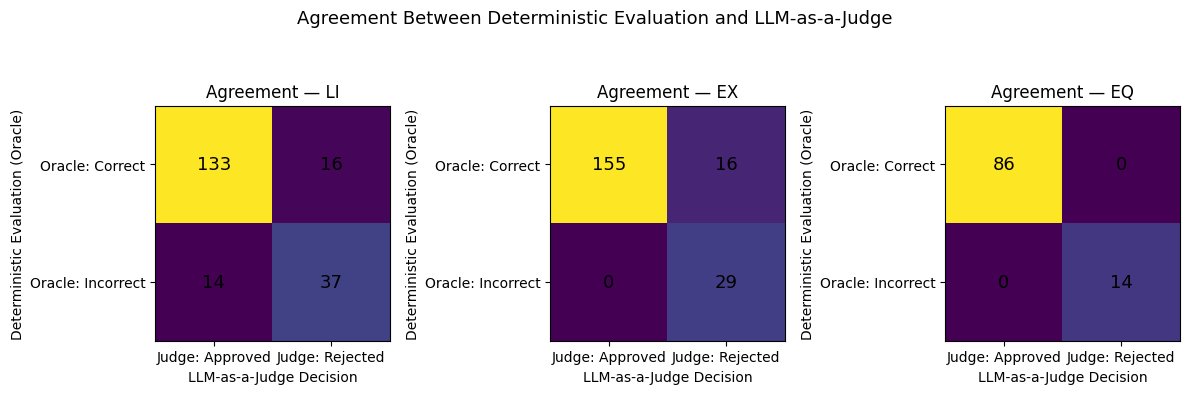

In [204]:
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion(df, title_suffix, ax):
    confusion = pd.crosstab(df["correct"], df["judge_approved"])
    confusion = confusion.reindex(index=[True, False], columns=[True, False], fill_value=0)
    confusion.index = ["Oracle: Correct", "Oracle: Incorrect"]
    confusion.columns = ["Judge: Approved", "Judge: Rejected"]

    im = ax.imshow(confusion.values)

    ax.set_xticks(np.arange(len(confusion.columns)))
    ax.set_yticks(np.arange(len(confusion.index)))
    ax.set_xticklabels(confusion.columns)
    ax.set_yticklabels(confusion.index)

    for i in range(confusion.shape[0]):
        for j in range(confusion.shape[1]):
            ax.text(j, i, confusion.iloc[i, j], ha="center", va="center", fontsize=13)

    ax.set_title(f"Agreement — {title_suffix}")
    ax.set_xlabel("LLM-as-a-Judge Decision")
    ax.set_ylabel("Deterministic Evaluation (Oracle)")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

plot_confusion(df_li, "LI", axes[0])
plot_confusion(df_ex, "EX", axes[1])
plot_confusion(df_eq, "EQ", axes[2])

fig.suptitle("Agreement Between Deterministic Evaluation and LLM-as-a-Judge", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

/var/folders/45/dkq6xf393dl237ykr6y1mxz40000gn/T/ipykernel_2400/2445398928.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  greens = cm.get_cmap("Greens")
/var/folders/45/dkq6xf393dl237ykr6y1mxz40000gn/T/ipykernel_2400/2445398928.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  reds = cm.get_cmap("Reds")


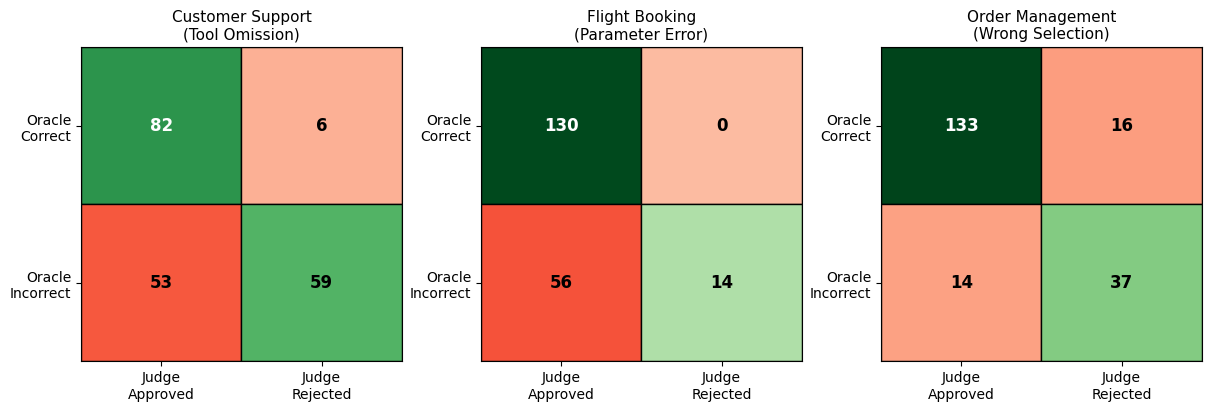

In [161]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.cm as cm
import numpy as np

matrices = {
    "Customer Support\n(Tool Omission)": np.array([
        [82, 6],
        [53, 59]
    ]),
    "Flight Booking\n(Parameter Error)": np.array([
        [130, 0],
        [56, 14]
    ]),
    "Order Management\n(Wrong Selection)": np.array([
        [133, 16],
        [14, 37]
    ])
}

vmax = max(m.max() for m in matrices.values())

greens = cm.get_cmap("Greens")
reds = cm.get_cmap("Reds")

fig, axes = plt.subplots(1, 3, figsize=(12,4), constrained_layout=True)

for ax, (title, matrix) in zip(axes, matrices.items()):

    ax.set_title(title, fontsize=11)

    for i in range(2):
        for j in range(2):

            value = matrix[i, j]
            intensity = value / vmax

            # Diagonal = concordância (verde)
            if i == j:
                color = greens(0.25 + 0.75*intensity)
            # Fora da diagonal = discordância (vermelho)
            else:
                color = reds(0.25 + 0.75*intensity)

            ax.add_patch(
                Rectangle(
                    (j-0.5, i-0.5),
                    1, 1,
                    facecolor=color,
                    edgecolor="black"
                )
            )

            # Calcula a luminância da cor (RGB)
            r, g, b, _ = color
            luminance = 0.299 * r + 0.587 * g + 0.114 * b
            
            text_color = "white" if luminance < 0.5 else "black"
            
            ax.text(
                j, i, str(value),
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold",
                color=text_color
            )


    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(1.5, -0.5)

    ax.set_xticks([0,1])
    ax.set_xticklabels(["Judge\nApproved","Judge\nRejected"])

    ax.set_yticks([0,1])
    ax.set_yticklabels(["Oracle\nCorrect","Oracle\nIncorrect"])


# PDF (vetorial, ideal para artigos)
plt.savefig(
    "confusion_matrices.pdf",
    bbox_inches="tight"
)

plt.show()

In [162]:
# fp por model

fp_count = (
    failures_df.groupby("model")["judge_approved"]
    .sum()
    .sort_values(ascending=False)
)

fp_count

model
Qwen/Qwen3-14B                           4
meta-llama/Meta-Llama-3.1-8B-Instruct    4
Qwen/Qwen2.5-7B-Instruct                 2
gpt-4o                                   2
gpt-4o-mini                              2
Name: judge_approved, dtype: int64

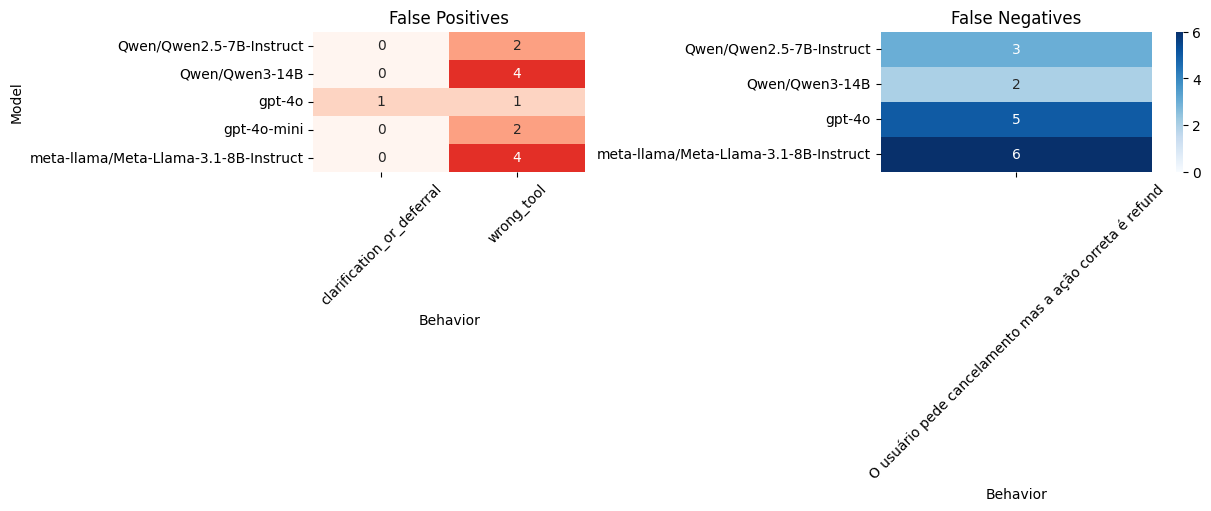

In [174]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# CONFIG
# ==========================================

FILE_PATHS = [
    "./falsos/selection_false_negatives - selection_false_negatives.csv",
    "./falsos/selection_false_positives - selection_false_positives.csv",
]

# ==========================================
# LOAD
# ==========================================

df_fn = pd.read_csv(FILE_PATHS[0])
df_fp = pd.read_csv(FILE_PATHS[1])

# ==========================================
# CROSSTABS
# ==========================================

heatmap_fn = pd.crosstab(
    df_fn["model"],
    df_fn["MOTIVO"]
)

heatmap_fp = pd.crosstab(
    df_fp["model"],
    df_fp["MOTIVO"]
)

# mesma escala para os dois heatmaps
vmax = max(
    heatmap_fn.values.max() if not heatmap_fn.empty else 0,
    heatmap_fp.values.max() if not heatmap_fp.empty else 0,
)

# ==========================================
# PLOT
# ==========================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    constrained_layout=True
)

sns.heatmap(
    heatmap_fp,
    annot=True,
    fmt="d",
    cmap="Reds",
    vmin=0,
    vmax=vmax,
    ax=axes[0],
    cbar=False
)

axes[0].set_title("False Positives")
axes[0].set_xlabel("Behavior")
axes[0].set_ylabel("Model")
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(
    heatmap_fn,
    annot=True,
    fmt="d",
    cmap="Blues",
    vmin=0,
    vmax=vmax,
    ax=axes[1],
    cbar=True
)

axes[1].set_title("False Negatives")
axes[1].set_xlabel("Behavior")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=45)

plt.show()

In [177]:
# resultados como tabela 

fp = pd.crosstab(df_fp["model"], df_fp["MOTIVO"])
fn = pd.crosstab(df_fn["model"], df_fn["MOTIVO"])

fp.columns = pd.MultiIndex.from_product([["False Positives"], fp.columns])
fn.columns = pd.MultiIndex.from_product([["False Negatives"], fn.columns])

table = pd.concat([fp, fn], axis=1).fillna(0).astype(int)

table["Total FP"] = fp.sum(axis=1)
table["Total FN"] = fn.sum(axis=1)

table

False Positives             \
MOTIVO                                clarification_or_deferral wrong_tool   
model                                                                        
Qwen/Qwen2.5-7B-Instruct                                      0          2   
Qwen/Qwen3-14B                                                0          4   
gpt-4o                                                        1          1   
gpt-4o-mini                                                   0          2   
meta-llama/Meta-Llama-3.1-8B-Instruct                         0          4   

                                                                              False Negatives  \
MOTIVO                                O usuário pede cancelamento mas a ação correta é refund   
model                                                                                           
Qwen/Qwen2.5-7B-Instruct                                                                    3   
Qwen/Qwen3-14B                                                                              2   
gpt-4o                                                                                      5   
gpt-4o-mini                                                                                 0   
meta-llama/Meta-Llama-3.1-8B-Instruct                                                       6   

                                      Total FP Total FN  
MOTIVO                                                   
model                                                    
Qwen/Qwen2.5-7B-Instruct                     2      3.0  
Qwen/Qwen3-14B                               4      2.0  
gpt-4o                                       2      5.0  
gpt-4o-mini                                  2      NaN  
meta-llama/Meta-Llama-3.1-8B-Instruct        4      6.0

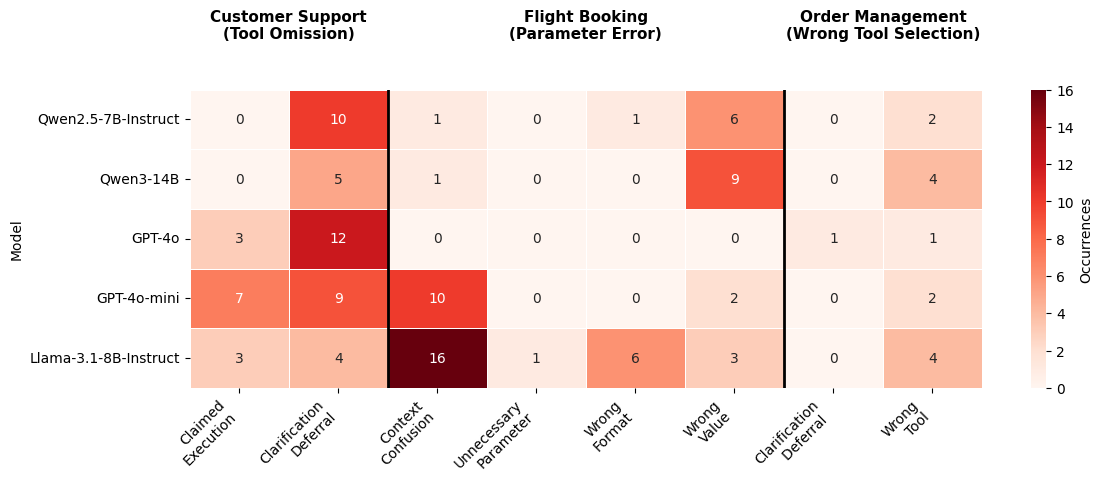

In [184]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# MODELS
# ==========================================

models = [
    "Qwen2.5-7B-Instruct",
    "Qwen3-14B",
    "GPT-4o",
    "GPT-4o-mini",
    "Llama-3.1-8B-Instruct",
]

# ==========================================
# AGENT 1
# ==========================================

agent1 = pd.DataFrame(
    {
        "Claimed\nExecution": [0, 0, 3, 7, 3],
        "Clarification\nDeferral": [10, 5, 12, 9, 4],
    },
    index=models,
)

# ==========================================
# AGENT 2
# ==========================================

agent2 = pd.DataFrame(
    {
        "Context\nConfusion": [1, 1, 0, 10, 16],
        "Unnecessary\nParameter": [0, 0, 0, 0, 1],
        "Wrong\nFormat": [1, 0, 0, 0, 6],
        "Wrong\nValue": [6, 9, 0, 2, 3],
    },
    index=models,
)

# ==========================================
# AGENT 3
# ==========================================

agent3 = pd.DataFrame(
    {
        "Clarification\nDeferral ": [0, 0, 1, 0, 0],  # espaço para evitar nome duplicado
        "Wrong\nTool": [2, 4, 1, 2, 4],
    },
    index=models,
)

# ==========================================
# MERGE
# ==========================================

heatmap = pd.concat(
    [agent1, agent2, agent3],
    axis=1
)

# ==========================================
# PLOT
# ==========================================

plt.figure(figsize=(12,5))

ax = sns.heatmap(
    heatmap,
    annot=True,
    fmt="d",
    cmap="Reds",
    linewidths=.5,
    linecolor="white",
    cbar_kws={"label": "Occurrences"}
)

# ==========================================
# SEPARATORS
# ==========================================

sep1 = agent1.shape[1]
sep2 = sep1 + agent2.shape[1]

ax.axvline(sep1, color="black", linewidth=2)
ax.axvline(sep2, color="black", linewidth=2)

# ==========================================
# AGENT LABELS
# ==========================================

ax.text(
    sep1/2,
    -0.8,
    "Customer Support\n(Tool Omission)",
    ha="center",
    va="bottom",
    fontsize=11,
    fontweight="bold",
)

ax.text(
    sep1 + agent2.shape[1]/2,
    -0.8,
    "Flight Booking\n(Parameter Error)",
    ha="center",
    va="bottom",
    fontsize=11,
    fontweight="bold",
)

ax.text(
    sep2 + agent3.shape[1]/2,
    -0.8,
    "Order Management\n(Wrong Tool Selection)",
    ha="center",
    va="bottom",
    fontsize=11,
    fontweight="bold",
)

ax.set_xlabel("")
ax.set_ylabel("Model")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.tight_layout()

plt.savefig(
    "assets/rq3_behavior_heatmap.pdf",
    format="pdf",
    bbox_inches="tight",
    dpi=300,
)

plt.show()

In [138]:
df_llama["blank_with_tool"] = (
    df_llama["tool_called"] &
    (df_llama["final_content"].fillna("").str.strip() == "")
)

df_llama["blank_without_tool"] = (
    (~df_llama["tool_called"]) &
    (df_llama["final_content"].fillna("").str.strip() == "")
)

summary = (
    df_llama.groupby(["model","case_id"])
      .agg(
          runs=("run","count"),
          blank_with_tool=("blank_with_tool","sum"),
          blank_without_tool=("blank_without_tool","sum"),
      )
)

summary

runs  blank_with_tool  \
model                                 case_id                          
meta-llama/Meta-Llama-3.1-8B-Instruct am_1       10                0   
                                      am_2       10                0   
                                      am_3       10                1   
                                      am_4       10                1   
                                      eq_1       10                0   
                                      eq_2       10                0   
                                      ex_1       10                1   
                                      ex_2       10                1   
                                      ex_3       10                0   
                                      ex_4       10                0   

                                               blank_without_tool  
model                                 case_id                      
meta-llama/Meta-Llama-3.1-8B-Instruct am_1                      8  
                                      am_2                      0  
                                      am_3                      0  
                                      am_4                      6  
                                      eq_1                     10  
                                      eq_2                      4  
                                      ex_1                      6  
                                      ex_2                      0  
                                      ex_3                      1  
                                      ex_4                      5

In [147]:
import numpy as np
import pandas as pd

df = df_llama.copy()

# =========================
# Ground truth (determinístico)
# =========================
df["oracle_accept"] = df["correct"].astype(int) == 1

# =========================
# Judge (LLM-as-a-judge)
# =========================
df["final_content"] = df["final_content"].fillna("").astype(str)

df["deepeval_score_filled"] = np.where(
    df["final_content"].str.strip() == "",
    0.0,
    df["deepeval_score"]
)

df["judge_accept"] = df["deepeval_score_filled"] >= 0.7

# =========================
# Casos
# =========================

# (1) ambos aprovam
both_accept = df[(df["oracle_accept"]) & (df["judge_accept"])]

# (2) ambos reprovam
both_reject = df[(~df["oracle_accept"]) & (~df["judge_accept"])]

# (3) determinístico aprova, judge reprova
oracle_accept_judge_reject = df[(df["oracle_accept"]) & (~df["judge_accept"])]

# (4) determinístico reprova, judge aprova
oracle_reject_judge_accept = df[(~df["oracle_accept"]) & (df["judge_accept"])]

# =========================
# Resultados
# =========================
print("Both accept:", len(both_accept))
print("Both reject:", len(both_reject))
print("Oracle accept / Judge reject:", len(oracle_accept_judge_reject))
print("Oracle reject / Judge accept:", len(oracle_reject_judge_accept))

Both accept: 27
Both reject: 46
Oracle accept / Judge reject: 18
Oracle reject / Judge accept: 9


In [118]:
# Side by side: fp_rate + count para df_li e df_ex
def fp_stats(df):
    return (
        df[df["correct"] == False]
        .groupby("model")["judge_approved"]
        .agg(
            total_incorrect="count",
            fp_count="sum",
            fp_rate=lambda x: round(x.mean() * 100, 1)
        )
    )

stats_li = fp_stats(df_li).add_suffix("_am")
stats_ex = fp_stats(df_ex).add_suffix("_ex")

result = pd.concat([stats_li, stats_ex], axis=1).sort_index()
result

,total_incorrect_am,fp_count_am,fp_rate_am,total_incorrect_ex,fp_count_ex,fp_rate_ex
model,,,,,,
Qwen/Qwen2.5-7B-Instruct,2,2,100.0,NaN,NaN,NaN
Qwen/Qwen3-14B,4,4,100.0,NaN,NaN,NaN
gpt-4o,13,2,15.4,17.0,0.0,0.0
gpt-4o-mini,10,2,20.0,NaN,NaN,NaN
meta-llama/Meta-Llama-3.1-8B-Instruct,22,4,18.2,12.0,0.0,0.0


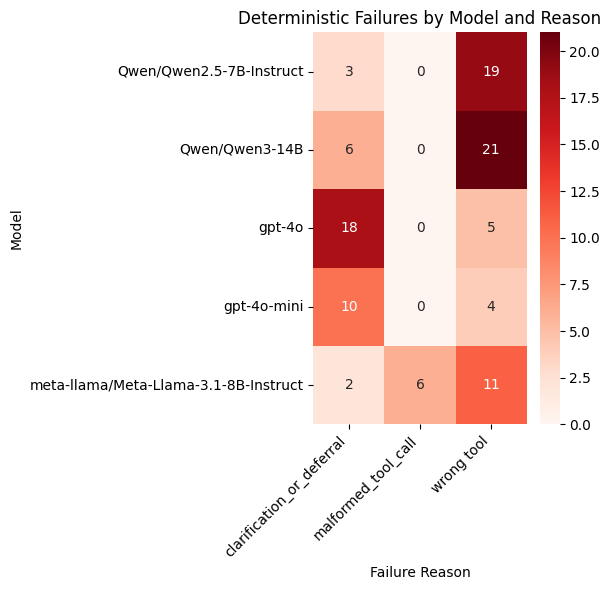

In [96]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# CONFIG
# ==========================================

FILE_PATH = "wrong_tool_sel_false_positives - false_positives.csv"  # ajuste aqui

# ==========================================
# LOAD CSV
# ==========================================

df_fp = pd.read_csv(FILE_PATH)

# ==========================================
# HEATMAP: MODEL x MOTIVO
# ==========================================

heatmap_data = pd.crosstab(
    df_fp["model"],
    df_fp["MOTIVO"]
)

# ==========================================
# PLOT
# ==========================================

fig, ax = plt.subplots(figsize=(6,6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="Reds",
    ax=ax
)

ax.set_xlabel("Failure Reason")
ax.set_ylabel("Model")
ax.set_title("Deterministic Failures by Model and Reason")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## ações feitas

In [99]:
import pandas as pd
import json
from collections import Counter


# # Filtra os falsos positivos de wrong tool
# fp = df[
#     (df["judge_approved"] == True) &
#     (df["MOTIVO"] == "wrong tool")
# ]

counter = Counter()

for tools in df_fp["tool_calls_info"].dropna():

    try:
        tool_list = json.loads(tools)

        for tool in tool_list:
            if isinstance(tool, dict) and "name" in tool:
                counter[tool["name"]] += 1

    except Exception:
        # ignora linhas malformadas
        pass

result = (
    pd.DataFrame(counter.items(), columns=["tool_name", "count"])
      .sort_values("count", ascending=False)
)

result["percentage"] = (
    result["count"] / result["count"].sum() * 100
).round(2)

print(result)

            tool_name  count  percentage
0      escalate_order     34       43.59
1  check_order_status     31       39.74
3        refund_order      8       10.26
2        update_order      3        3.85
4       process_order      2        2.56


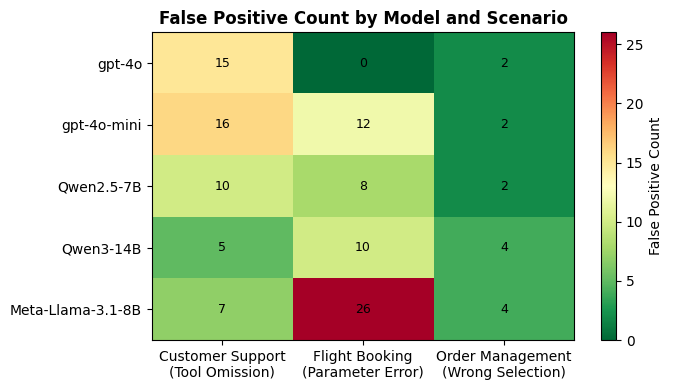

In [171]:
import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs("assets", exist_ok=True)

# ==========================================
# DATA
# ==========================================

models = [
    "gpt-4o",
    "gpt-4o-mini",
    "Qwen2.5-7B",
    "Qwen3-14B",
    "Meta-Llama-3.1-8B",
]

scenario_failure = [
    "Customer Support\n(Tool Omission)",
    "Flight Booking\n(Parameter Error)",
    "Order Management\n(Wrong Selection)",
]

# Número de falsos positivos
fp_counts = np.array([
    [15,  0, 2],   # gpt-4o
    [16, 12, 2],   # gpt-4o-mini
    [10,  8, 2],   # Qwen2.5-7B
    [ 5, 10, 4],   # Qwen3-14B
    [ 7, 26, 4],   # Meta-Llama-3.1-8B
])

# ==========================================
# FIGURE
# ==========================================

fig, ax = plt.subplots(figsize=(7, 4))

im = ax.imshow(fp_counts, cmap="RdYlGn_r", aspect="auto")

ax.set_xticks(range(len(scenario_failure)))
ax.set_xticklabels(scenario_failure)

ax.set_yticks(range(len(models)))
ax.set_yticklabels(models)

ax.set_title("False Positive Count by Model and Scenario", fontweight="bold")

for i in range(len(models)):
    for j in range(len(scenario_failure)):
        val = fp_counts[i, j]
        color = "black"  # ajuste do limiar para contagens
        ax.text(
            j, i, str(val),
            ha="center", va="center",
            fontsize=9, color=color
        )

plt.colorbar(im, ax=ax, label="False Positive Count")

plt.tight_layout()
plt.savefig("assets/fp_rate_rq2.pdf", bbox_inches="tight")
plt.show()

In [60]:
fp_count = (
    failures_df.groupby("model")["judge_approved"]
    .sum()
    .sort_values(ascending=False)
)

fp_count

model
Qwen/Qwen3-14B                           27
gpt-4o                                   25
Qwen/Qwen2.5-7B-Instruct                 22
meta-llama/Meta-Llama-3.1-8B-Instruct    19
gpt-4o-mini                              14
Name: judge_approved, dtype: int64

model
Qwen/Qwen3-14B                           27
gpt-4o                                   25
Qwen/Qwen2.5-7B-Instruct                 22
meta-llama/Meta-Llama-3.1-8B-Instruct    19
gpt-4o-mini                              14
Name: judge_approved, dtype: int64
TOTAL: 107


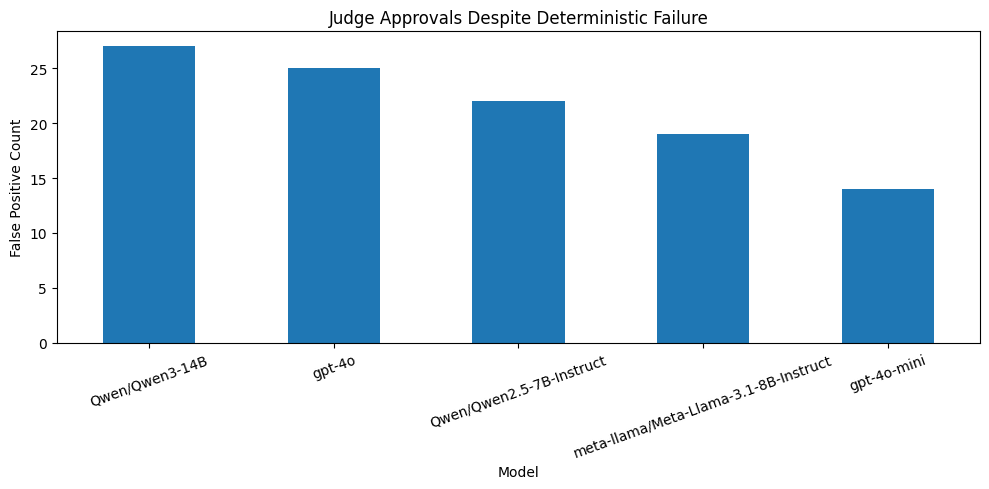

In [61]:
# ==========================================
# FIGURE 2 — FALSE POSITIVES BY MODEL
# ==========================================

fp_count = (
    failures_df.groupby("model")["judge_approved"]
    .sum()
    .sort_values(ascending=False)
)

print(fp_count)
print("TOTAL:", fp_count.sum())

plt.figure(figsize=(10, 5))

fp_count.plot(kind="bar")

plt.ylabel("False Positive Count")
plt.xlabel("Model")

plt.title(
    "Judge Approvals Despite Deterministic Failure"
)

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

                                               True Positives  False Positives
case_id model                                                                 
hi_1    Qwen/Qwen2.5-7B-Instruct                         10.0              0.0
        Qwen/Qwen3-14B                                   10.0              0.0
        gpt-4o                                           10.0              0.0
        gpt-4o-mini                                      10.0              0.0
        meta-llama/Meta-Llama-3.1-8B-Instruct             6.0              0.0
...                                                       ...              ...
li_2    Qwen/Qwen3-14B                                    0.0              9.0
        gpt-4o                                            0.0             10.0
        gpt-4o-mini                                       0.0             10.0
li_3    Qwen/Qwen2.5-7B-Instruct                          0.0             10.0
        Qwen/Qwen3-14B                              

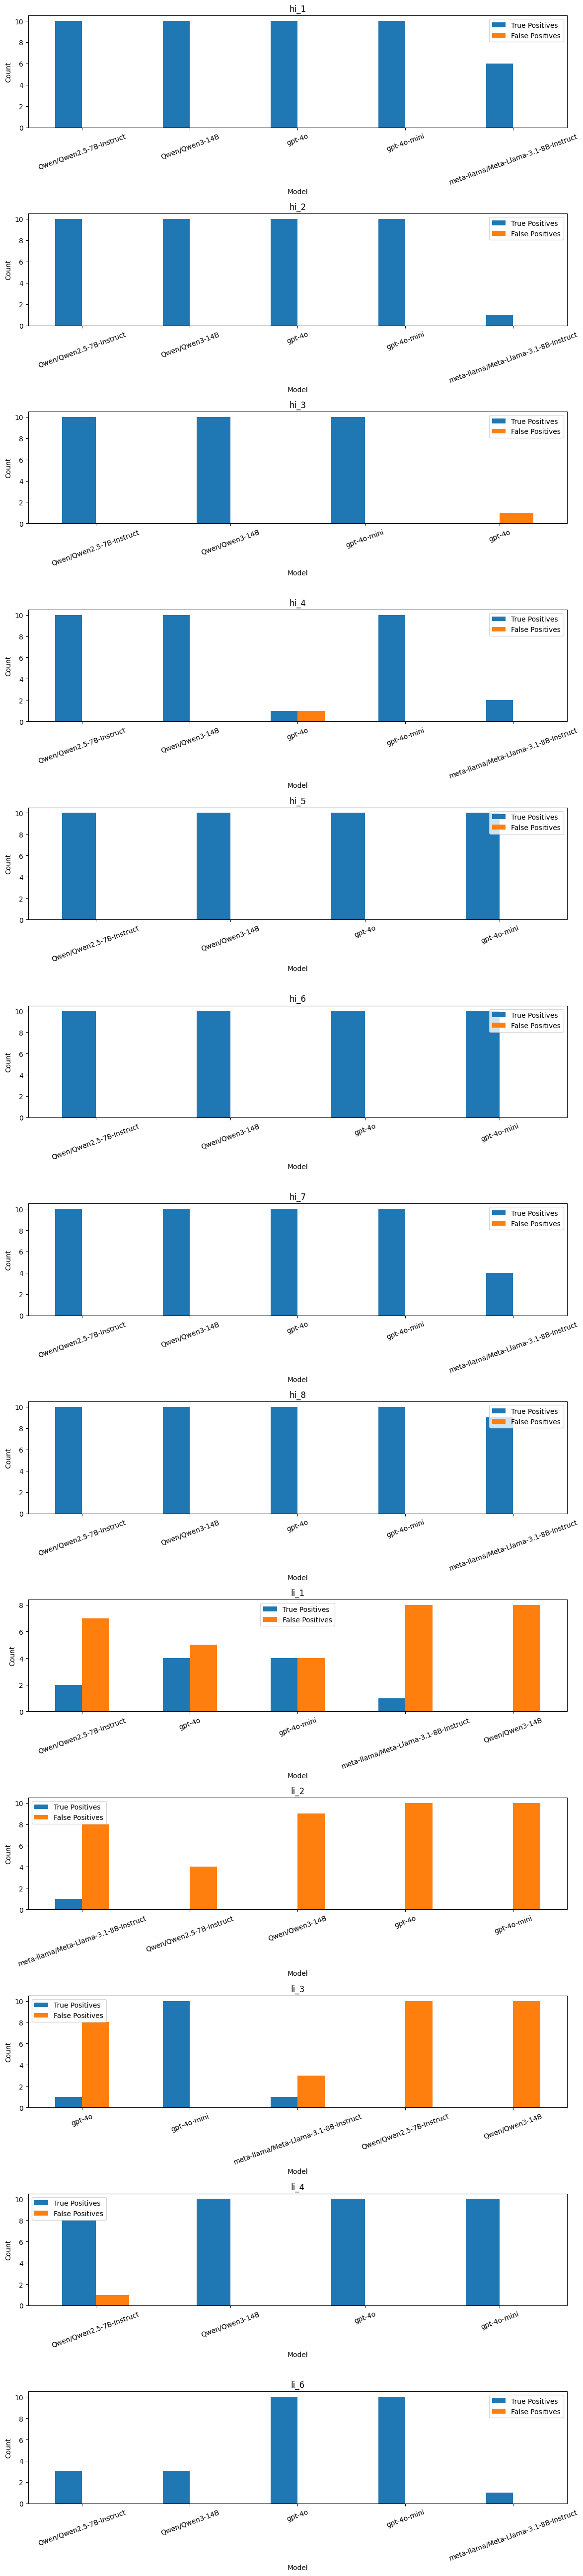

In [62]:
# ==========================================
# TP vs FP BY MODEL AND CASE
# ==========================================

# True Positives
tp_df = df[
    (df["correct"] == True) &
    (df["judge_approved"] == True)
]

# False Positives
fp_df = df[
    (df["correct"] == False) &
    (df["judge_approved"] == True)
]

tp_count = (
    tp_df.groupby(["case_id", "model"])
    .size()
    .rename("True Positives")
)

fp_count = (
    fp_df.groupby(["case_id", "model"])
    .size()
    .rename("False Positives")
)

comparison = pd.concat(
    [tp_count, fp_count],
    axis=1
).fillna(0)

print(comparison)

# ==========================================
# PLOT
# ==========================================

case_ids = comparison.index.get_level_values(0).unique()

fig, axes = plt.subplots(
    nrows=len(case_ids),
    figsize=(12, 4 * len(case_ids))
)

if len(case_ids) == 1:
    axes = [axes]

for ax, case_id in zip(axes, case_ids):

    case_data = comparison.loc[case_id]

    case_data.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(f"{case_id}")
    ax.set_ylabel("Count")
    ax.set_xlabel("Model")

    ax.tick_params(
        axis="x",
        rotation=20
    )

plt.tight_layout()
plt.show()

In [ ]:
# falsos positivos e threshold sensitivity

In [225]:
import pandas as pd

file_paths = [
    "./falsos/selection_false_positives - selection_false_positives.csv",
    "../../tool_omission/results/falsos/omission_false_positives - omission_false_positives.csv",
    "../../parameter_error/results/falsos/parameter_false_positives - parameter_false_positives (3).csv"
]

dfs = []

for path in file_paths:
    df = pd.read_csv(path)
    df["source_file"] = path.split("/")[-1]
    dfs.append(df)

fp_df = pd.concat(dfs, ignore_index=True)

thresholds = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0]

rows = []

for t in thresholds:
    fp_count = (fp_df["deepeval_score"] >= t).sum()
    rows.append((t, fp_count))

df_plot = pd.DataFrame(rows, columns=["threshold", "fp_count"])

print(df_plot)

   threshold  fp_count
0       0.50       123
1       0.60       123
2       0.70       123
3       0.80        94
4       0.90        94
5       0.95        61
6       1.00        55


In [226]:
latex_table = df_plot.to_latex(
    index=False,
    float_format="%.2f"
)

print(latex_table)

\begin{tabular}{rr}
\toprule
threshold & fp_count \\
\midrule
0.50 & 123 \\
0.60 & 123 \\
0.70 & 123 \\
0.80 & 94 \\
0.90 & 94 \\
0.95 & 61 \\
1.00 & 55 \\
\bottomrule
\end{tabular}

